# Dyad sampling with workers

Sampling reduces the pairs each SPI visits; workers divide the SPIs. The dyads are fixed before any work is handed out, so a sampled run is one array whatever the number of workers.

In [1]:
import json, os, sys, tempfile, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
warnings.simplefilter("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"      # spawned workers too

BENCH = Path("../../bench/pair_sampling"); sys.path.insert(0, str(BENCH))
import validate as V
from pyspi.calculator import Calculator

plt = V.figure_style(backend=None)
plt.rcParams["figure.dpi"] = 110
RESULTS, GADI = BENCH / "results", BENCH / "results" / "gadi-smoke"

## 1. One result; checkpoints tied to the sample

In [2]:
x = V.var_series(M=20, T=500, seed=0)
calc = Calculator(dataset=x, config="select.yaml", verbose=False)
serial = calc.compute_pairs(n_pairs=40, seed=1, progress=False).copy()

with tempfile.TemporaryDirectory() as checkpoints:
    workers = calc.compute_pairs(n_pairs=40, seed=1, n_jobs=2, checkpoint_dir=checkpoints, progress=False).copy()
    resumed = calc.compute_pairs(n_pairs=40, seed=1, checkpoint_dir=checkpoints, progress=False)
    print("two workers == serial:", np.array_equal(workers, serial),
          "| resumed == serial:", np.array_equal(resumed, serial),
          "| recomputed on resume:", sum(t > 0 for t in calc.timings.values()))
    for label, call in (("another sample", lambda: calc.compute_pairs(n_pairs=40, seed=2, checkpoint_dir=checkpoints, progress=False)),
                        ("the full table", lambda: calc.compute(checkpoint_dir=checkpoints, progress=False))):
        try:
            call()
        except ValueError as error:
            print(f"{label}: refused ({str(error).split('(')[1].split(')')[0]})")

two workers == serial:

True

| resumed == serial:

True

| recomputed on resume:

0

another sample: refused (checkpoint was written by a different run)

the full table: refused (checkpoint was written by a different run)

## 2. Both together, $M=20$, $T=1000$ (local, `benchmarked_p90`)

Wall time for the full table and for two budgets on 1, 2 and 4 spawned workers. The fully computed SPIs and the pool start-up do not shrink with $b$, so workers add least where sampling has already removed most of the work.

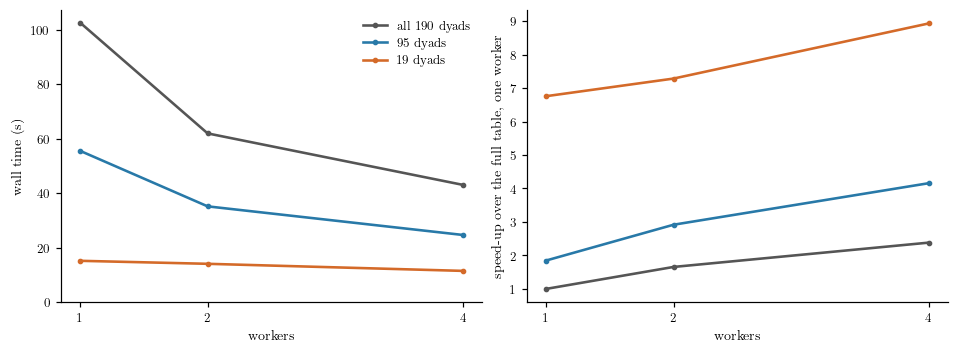

n_jobs,1,2,4
run,,,
all 190 dyads,102.7,62.0,43.1
95 dyads,55.6,35.2,24.7
19 dyads,15.2,14.1,11.5


In [3]:
w = pd.read_csv(RESULTS / "workers.csv")
w["run"] = np.where(w.n_pairs == "all", "all 190 dyads", w.n_pairs + " dyads")
colors = dict(zip(w.run.unique(), ["#555555", "#2879a8", "#d46a29"]))
fig, (a, b) = plt.subplots(1, 2, figsize=(8.6, 3.1))
for run, part in w.groupby("run", sort=False):
    a.plot(part.n_jobs, part.wall_s, "o-", color=colors[run], label=run)
    b.plot(part.n_jobs, w.wall_s.iloc[0] / part.wall_s, "o-", color=colors[run])
a.set(xlabel="workers", ylabel="wall time (s)", xticks=[1, 2, 4], ylim=(0, None)); a.legend()
b.set(xlabel="workers", ylabel="speed-up over the full table, one worker", xticks=[1, 2, 4])
plt.show()
w.pivot(index="run", columns="n_jobs", values="wall_s").loc[list(colors)]

In [4]:
same = w.groupby("run", sort=False).values_sha256.nunique().eq(1)
print("result hash identical across worker counts:", {k: bool(v) for k, v in same.items()})

result hash identical across worker counts:

{'all 190 dyads': True, '95 dyads': True, '19 dyads': True}

## 3. One MEG recording on Gadi, $M=243$, $T=1000$

$D = 29{,}403$ dyads. The full extraction of this recording took 19.3 h on one core. Sampled runs at $b=1000$ on 1, 4 and 8 forked workers and at $b=2500$ on 8, each job bound by PBS to its cores.

In [5]:
if (GADI / "summary.json").exists():
    summary = json.loads((GADI / "summary.json").read_text())
    g = pd.DataFrame(summary["runs"]).query("M == 243").reset_index(drop=True)
    display(g[["run", "n_pairs", "n_jobs", "bound_cores", "wall_hours", "spi_seconds", "pbs_mem_gib",
               "largest_worker_rss_gib", "failed"]].round(2))
    for key in ("m243_dense_reference", "m243_vs_dense", "m243_z_error"):
        print(summary[key])
    print("identical across worker counts:", summary["identical_across_workers"]["m243-b1000"],
          "| b=2500 run starts with the b=1000 dyads and values:", summary["nested_prefix_identical"])

In [6]:
if (GADI / "summary.json").exists():
    part = g[g.n_pairs == 1000].sort_values("n_jobs")
    fig, (a, b) = plt.subplots(1, 2, figsize=(8.6, 3.1))
    a.plot(part.n_jobs, part.wall_hours * 60, "o-", color="#3b9b78", label=r"$b=1000$")
    a.plot(part.n_jobs, part.wall_hours.iloc[0] * 60 / part.n_jobs, color=".5", ls="--", lw=1, label=r"ideal $1/k$")
    big = g[g.n_pairs == 2500]
    a.plot(big.n_jobs, big.wall_hours * 60, "D", color="#d46a29", label=r"$b=2500$")
    a.set(xlabel="workers", ylabel="wall time (min)", xticks=part.n_jobs); a.legend()
    b.bar(g.run.str.replace("m243-", ""), g.pbs_mem_gib, color="#3b9b78")
    b.set(ylabel="job peak memory (GiB, PBS)"); b.tick_params(axis="x", labelrotation=20)
    plt.show()

A full matrix from the earlier extraction with the sampled dyads marked, and the sampled entries against the full ones for four statistics.

In [7]:
if (GADI / "m243-examples.npz").exists():
    ex = np.load(GADI / "m243-examples.npz", allow_pickle=False)
    i, j = ex["pairs"].T
    names = [str(n) for n in ex["names"]]
    fig, axes = plt.subplots(1, 5, figsize=(12.5, 2.7), gridspec_kw=dict(width_ratios=[1.25, 1, 1, 1, 1]))
    S = ex["dense"][0].astype(float); np.fill_diagonal(S, np.nan)
    lim = np.nanquantile(np.abs(S), .995)
    axes[0].imshow(S, cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[0].plot(np.r_[j, i], np.r_[i, j], ",", color="k", alpha=.6)
    axes[0].set(xticks=[], yticks=[], title=names[0] + r" ($b=1000$ marked)")
    for ax, name, dense, sampled in zip(axes[1:], names, ex["dense"], ex["sampled"]):
        full = np.r_[dense[i, j], dense[j, i]]; got = np.r_[sampled[:, 0], sampled[:, 1]]
        ax.plot(full, got, ".", ms=2, color="#3b9b78")
        ax.axline((np.nanmin(full), np.nanmin(full)), slope=1, color=".5", lw=.6)
        ax.set(title=name, xlabel="full extraction")
    axes[1].set_ylabel("sampled run")
    plt.show()